# Sentinel-1 change: backscatter before and after the fire season

Reads the outputs of the optional jobs `job.s1_composite` and `job.gsw` and of `job.forest_typology` (step 2b), see the README, for the area of interest (AOI) of `.env` (the GADM provinces in `PROVINCES`, Kalimantan Tengah in the example), loaded as in `firms.ipynb`. The notebook:

1. plots the AOI,
2. plots the Sentinel-1 composites of the two periods of `S1_PERIODS` (by default 1 to 14 June 2026, before the fire season, and 1 to 14 November 2026, after it): VV, VH and the cross-polarisation ratio VH - VV (dB),
3. plots the JRC Global Surface Water occurrence (1984 to 2024),
4. plots the Forest Typology 2020 land cover,
5. masks the Sentinel-1 composites where the water occurrence is above `MAX_WATER_OCCURRENCE` (10%), so rivers, lakes and often flooded land do not show as change, and where the land cover is other land, so only the forest and tree crops (classes 1 to 5) are kept,
6. subtracts June from November for VV, VH and VH - VV, in percent of June, and keeps only the pixels where November is lower than June,
7. keeps only the decreases of more than `STRONG_DECREASE` (10%).

Everything is read and computed at `RESOLUTION` (100 m), from the overviews of the 30 m files, so the notebook runs on a laptop: a 100 m pixel is the average of about 11 pixels of 30 m, and the Forest Typology class is the most common class of its 30 m pixels. VV, VH and VH - VV are shown in decibels (dB); their change is computed from the linear values, in percent of June.

A lower backscatter in November than in June is a change of the radar signal, not a burned area: it can come from fire, clearing, harvest, a wetter or drier surface, or the different dates and orbits in each composite. Compare it with the FIRMS alerts of `firms.ipynb` before drawing conclusions.

In [1]:
import os

# Run from the repository root, also when the notebook is opened from notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")

import contextily as cx
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from rasterio.enums import Resampling
from rasterio.transform import from_bounds
from rasterio.warp import reproject

from forest_fire.aoi import read_provinces
from forest_fire.config import (
    AOI_NAME,
    AOI_TITLE,
    COUNTRY,
    FIGURE_DIR,
    FOREST_TYPOLOGY_DIR,
    FOREST_TYPOLOGY_RESOLUTION,
    GSW_DIR,
    GSW_RESOLUTION,
    S1_DIR,
    S1_PERIODS,
    S1_RESOLUTION,
)

# Lower resolution figures, keeps the notebook small
plt.rcParams["figure.dpi"] = 60
plt.rcParams["font.size"] = 14

# Pixel size of the analysis and the maps in metres, read from the overviews of the 30 m files
RESOLUTION = 100
# Pixels with water in more than this percentage of the observations of 1984 to 2024 are masked
MAX_WATER_OCCURRENCE = 10

# The composites of job.s1_composite, the first period before the fire season and the last after it
(BEFORE_START, BEFORE_END), (AFTER_START, AFTER_END) = S1_PERIODS[0], S1_PERIODS[-1]
S1_PATHS = {
    "before": S1_DIR / f"{AOI_NAME}_s1_rtc_{BEFORE_START}_{BEFORE_END}_{S1_RESOLUTION}m.tif",
    "after": S1_DIR / f"{AOI_NAME}_s1_rtc_{AFTER_START}_{AFTER_END}_{S1_RESOLUTION}m.tif",
}
PERIOD_TITLES = {"before": f"{BEFORE_START} to {BEFORE_END}", "after": f"{AFTER_START} to {AFTER_END}"}
GSW_PATH = GSW_DIR / f"{AOI_NAME}_gsw_{GSW_RESOLUTION}m.tif"
# Forest Typology 2020 of job.forest_typology, the class is band 7
FOREST_TYPOLOGY_PATH = FOREST_TYPOLOGY_DIR / f"{AOI_NAME}_forest_typology_{FOREST_TYPOLOGY_RESOLUTION}m.tif"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print(f"{AOI_TITLE} ({COUNTRY}): {PERIOD_TITLES['before']} and {PERIOD_TITLES['after']}, {RESOLUTION} m")

Kalimantan Tengah (IDN): 2026-06-01 to 2026-06-14 and 2026-11-01 to 2026-11-14, 100 m


## Map helpers

In [2]:
def add_lonlat(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):.1f}°{'E' if x >= 0 else 'W'}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{abs(y):.1f}°{'N' if y >= 0 else 'S'}"))
    ax.tick_params(labelsize="small")
    # The ticks already say °E and °N
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(color="grey", linewidth=0.4, alpha=0.6, linestyle="--")


def set_extent(ax, gdf, pad_frac=0.03):
    xmin, ymin, xmax, ymax = gdf.total_bounds
    pad = pad_frac * max(xmax - xmin, ymax - ymin)
    ax.set_xlim(xmin - pad, xmax + pad)
    ax.set_ylim(ymin - pad, ymax + pad)
    ax.set_aspect("equal")


def add_basemap(ax, **kwargs):
    # Light hillshade under the maps, the masked pixels show it
    cx.add_basemap(ax, crs="EPSG:4326", source=cx.providers.Esri.WorldShadedRelief, attribution_size=8, **kwargs)


def map_row(layers, title, file_name, ncols=None, width=8):
    """One map per layer, a layer is a dict of data (masked array), title, cmap, vmin, vmax and label.

    A layer with ``rgb=True`` has data of shape (rows, columns, 4), red, green, blue and alpha
    between 0 and 1, drawn as it is without a colour bar. A layer with ``handles`` gets a legend
    of these handles instead of a colour bar.
    """
    ncols = ncols or len(layers)
    nrows = int(np.ceil(len(layers) / ncols))
    xmin, ymin, xmax, ymax = aoi.total_bounds
    height = width * (ymax - ymin) / (xmax - xmin)
    fig, axes = plt.subplots(nrows, ncols, figsize=(width * ncols, (height + 1.2) * nrows), squeeze=False)
    for ax, layer in zip(axes.flat, layers):
        if layer.get("rgb"):
            image = ax.imshow(layer["data"], extent=extent, interpolation="nearest", zorder=2)
        else:
            image = ax.imshow(
                layer["data"],
                extent=extent,
                cmap=layer["cmap"],
                vmin=layer.get("vmin"),
                vmax=layer.get("vmax"),
                interpolation="nearest",
                zorder=2,
            )
        aoi.boundary.plot(ax=ax, color="black", linewidth=0.8, zorder=3)
        set_extent(ax, aoi)
        add_basemap(ax, zorder=1)
        add_lonlat(ax)
        ax.set_title(layer["title"], fontsize="medium")
        if layer.get("handles"):
            ax.legend(handles=layer["handles"], loc="upper right", fontsize="small")
        elif not layer.get("rgb"):
            fig.colorbar(image, ax=ax, shrink=0.7, label=layer.get("label", ""))
    for ax in axes.flat[len(layers) :]:
        ax.remove()
    fig.suptitle(title, fontsize="large")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"{AOI_NAME}_{file_name}.png", dpi=100, bbox_inches="tight")
    plt.show()

## 1. Area of interest

The GADM provinces of `PROVINCES` in `.env`, read with `forest_fire.aoi.read_provinces` as in `firms.ipynb` and by the jobs.

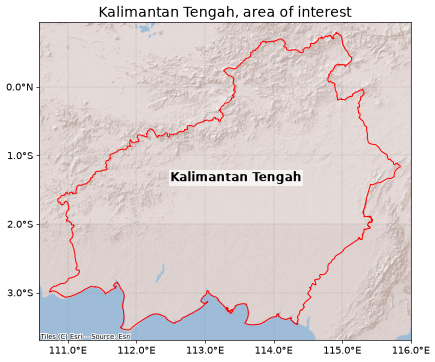

,name
province,
kalimantan_tengah,Kalimantan Tengah


In [3]:
aoi = read_provinces()

fig, ax = plt.subplots(figsize=(8, 8))
aoi.boundary.plot(ax=ax, color="red", linewidth=1.2, zorder=2)
for _, row in aoi.iterrows():
    point = row.geometry.representative_point()
    ax.text(point.x, point.y, row["name"], ha="center", fontweight="bold", zorder=3,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=2))
set_extent(ax, aoi)
add_basemap(ax, zorder=1)
add_lonlat(ax)
ax.set_title(f"{AOI_TITLE}, area of interest")
plt.show()
aoi.drop(columns="geometry")

## 2. Sentinel-1 composites

The median of the OPERA RTC-S1 backscatter (gamma0) of the dates of each period, from `job.s1_composite`, read at `RESOLUTION` with the average of the linear values. The files store gamma0 x 10,000, 0 is nodata.

- **VV** (vertical send, vertical receive) is stronger from rough and bare surfaces and from trunks and branches.
- **VH** (vertical send, horizontal receive) comes mostly from volume scattering in the canopy, so it is the band most sensitive to the loss of vegetation.
- **VH - VV** in dB, the cross-polarisation ratio VH / VV. VH is lower than VV almost everywhere, so it is negative: about -6 dB over dense forest, lower where the canopy, and so VH, is thin or lost.

The maps show the three bands as one colour composite: red VV, green VH and blue VH - VV, each stretched between its 2nd and 98th percentile of both periods, so the same colour means the same values in June and November. Forest has a strong VH and a high VH - VV, so it looks pale yellow to cyan. Where the canopy is thin or lost, VH and VH - VV drop while VV stays, and the land turns orange to brown (in the example the tree crops of the south west, and more of them in November). Dark blue is a low VV and VH with a high VH - VV, as on wet or smooth ground. The stretch of each band is printed below the cell.

In [4]:
def read_band(path, band, nodata=None):
    """One band at RESOLUTION, from the overviews, as a masked float array."""
    with rasterio.open(path) as src:
        factor = RESOLUTION / (src.res[0] * 111_000)
        shape = (max(1, round(src.height / factor)), max(1, round(src.width / factor)))
        data = src.read(band, out_shape=shape, resampling=Resampling.average, masked=True).astype("float32")
        bounds = src.bounds
    return data, (bounds.left, bounds.right, bounds.bottom, bounds.top)


def to_db(linear):
    return 10 * np.ma.log10(linear)


s1 = {}
for period, path in S1_PATHS.items():
    vv, extent = read_band(path, 1)
    vh, _ = read_band(path, 2)
    # Back to gamma0, the files store gamma0 x 10,000
    vv, vh = vv / 10_000, vh / 10_000
    # VH - VV in dB, the ratio VH / VV
    s1[period] = dict(vv=to_db(vv), vh=to_db(vh), ratio=to_db(vh) - to_db(vv))
    with rasterio.open(path) as src:
        print(f"{PERIOD_TITLES[period]}: dates {src.tags()['dates']}")

shape = s1["before"]["vv"].shape
print(f"{shape[1]} x {shape[0]} pixels of {RESOLUTION} m, extent {[round(v, 3) for v in extent]}")
for period, bands in s1.items():
    print(PERIOD_TITLES[period], {name: f"median {np.ma.median(band):.2f}" for name, band in bands.items()})

2026-06-01 to 2026-06-14: dates 2026-06-02, 2026-06-04, 2026-06-09, 2026-06-11, 2026-06-14


2026-11-01 to 2026-11-14: dates 2026-11-02, 2026-11-07, 2026-11-09, 2026-11-12, 2026-11-14
5678 x 4814 pixels of 100 m, extent [110.732, 115.847, -3.544, 0.793]


2026-06-01 to 2026-06-14 {'vv': 'median -5.97', 'vh': 'median -12.43', 'ratio': 'median -6.39'}


2026-11-01 to 2026-11-14 {'vv': 'median -6.20', 'vh': 'median -12.27', 'ratio': 'median -6.03'}


VV (dB): stretched from -9.48 to -4.30
VH (dB): stretched from -16.18 to -10.84
VH - VV (dB): stretched from -8.72 to -4.62


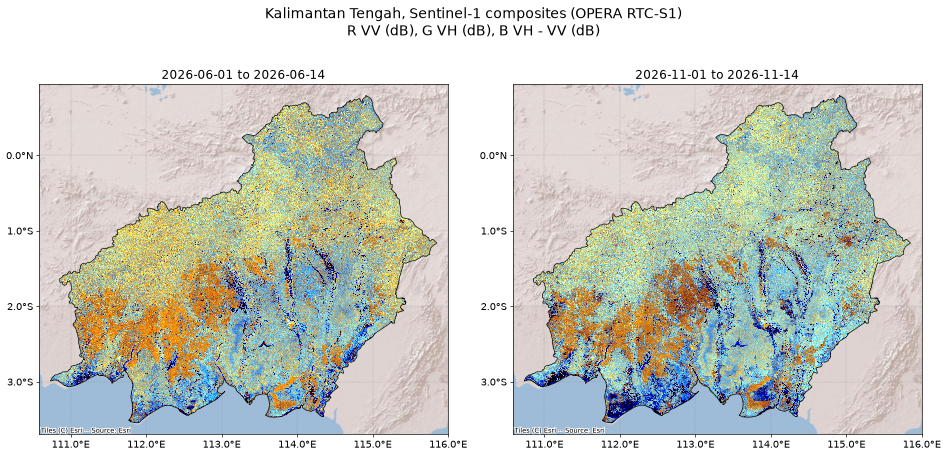

In [5]:
# Red VV, green VH, blue VH - VV. Each band is stretched between its 2nd and 98th
# percentile of both periods together, so the colours of the two periods compare
RGB_BANDS = {"vv": "VV (dB)", "vh": "VH (dB)", "ratio": "VH - VV (dB)"}
STRETCH = {
    band: np.percentile(np.concatenate([s1[period][band].compressed() for period in s1]), [2, 98])
    for band in RGB_BANDS
}
RGB_TITLE = f"R {RGB_BANDS['vv']}, G {RGB_BANDS['vh']}, B {RGB_BANDS['ratio']}"
for band, (low, high) in STRETCH.items():
    print(f"{RGB_BANDS[band]}: stretched from {low:.2f} to {high:.2f}")


def rgb(bands):
    """Red, green, blue and alpha between 0 and 1, transparent where a band has no data."""
    channels = [np.clip((bands[band].filled(np.nan) - low) / (high - low), 0, 1) for band, (low, high) in STRETCH.items()]
    image = np.dstack(channels)
    alpha = (~np.isnan(image).any(axis=2)).astype("float32")
    return np.dstack([np.nan_to_num(image), alpha])


def s1_layers(data):
    return [dict(data=rgb(data[period]), title=PERIOD_TITLES[period], rgb=True) for period in ("before", "after")]


map_row(s1_layers(s1), f"{AOI_TITLE}, Sentinel-1 composites (OPERA RTC-S1)\n{RGB_TITLE}", "s1_composites")

## 3. Surface water occurrence

JRC Global Surface Water v1.5 occurrence from `job.gsw`: the percentage of the valid Landsat observations of 1984 to 2024 in which the pixel was water, 100 for permanent water. At `RESOLUTION` it is the average of the 30 m pixels, so a 100 m pixel crossed by a narrow river has a low occurrence. Pixels without water (0) are not coloured.

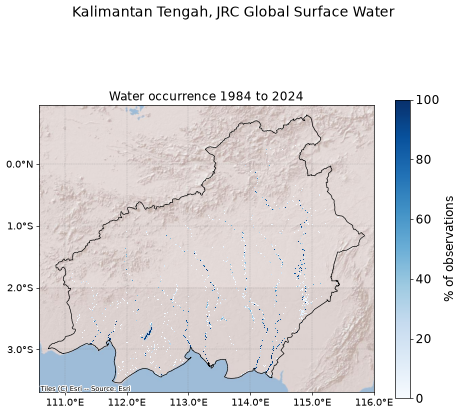

1.1% of the pixels above 10% occurrence


In [6]:
occurrence, _ = read_band(GSW_PATH, 1)
assert occurrence.shape == shape, "job.gsw and job.s1_composite must be on the same grid, run them with the same AOI"

water = np.ma.masked_where(occurrence == 0, occurrence)
map_row(
    [dict(data=water, title="Water occurrence 1984 to 2024", cmap="Blues", vmin=0, vmax=100, label="% of observations")],
    f"{AOI_TITLE}, JRC Global Surface Water",
    "gsw_occurrence",
)
print(f"{(occurrence > MAX_WATER_OCCURRENCE).sum() / occurrence.count():.1%} of the pixels above {MAX_WATER_OCCURRENCE}% occurrence")

## 4. Forest Typology 2020

The land cover of Forest Typology 2020 v1 (Google DeepMind, WRI, UMD and IIASA, CC BY 4.0) from `job.forest_typology`, as in `firms.ipynb`: the most probable of its 6 classes, reprojected from `FOREST_TYPOLOGY_RESOLUTION` (30 m) onto the grid of the Sentinel-1 maps with the most common class. It shows 2020, not the land cover of 2026.

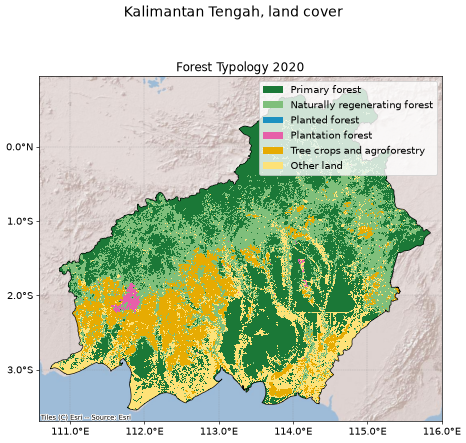

Primary forest 43.6%, Naturally regenerating forest 27.3%, Planted forest 0.0%, Plantation forest 0.6%, Tree crops and agroforestry 13.0%, Other land 15.5%


In [7]:
# Classes of Forest Typology 2020 with the colours of firms.ipynb
LAND_COVER = {
    1: ("Primary forest", "#1b7837"),
    2: ("Naturally regenerating forest", "#7fbf7b"),
    3: ("Planted forest", "#1d91c0"),
    4: ("Plantation forest", "#e65fa9"),
    5: ("Tree crops and agroforestry", "#e6ab02"),
    6: ("Other land", "#fde278"),
}
# Classes kept for the change, every class but other land
FOREST_CLASSES = [1, 2, 3, 4, 5]
FOREST_NODATA = 255

# The class band onto the grid of the Sentinel-1 maps, the most common class of the 30 m pixels
grid_transform = from_bounds(extent[0], extent[2], extent[1], extent[3], shape[1], shape[0])
land_cover = np.full(shape, FOREST_NODATA, dtype="uint8")
with rasterio.open(FOREST_TYPOLOGY_PATH) as src:
    reproject(
        rasterio.band(src, 7),
        land_cover,
        src_nodata=FOREST_NODATA,
        dst_transform=grid_transform,
        dst_crs="EPSG:4326",
        dst_nodata=FOREST_NODATA,
        resampling=Resampling.mode,
    )
land_cover = np.ma.masked_equal(land_cover, FOREST_NODATA)

map_row(
    [
        dict(
            data=land_cover,
            title="Forest Typology 2020",
            cmap=ListedColormap([color for _, color in LAND_COVER.values()]),
            vmin=0.5,
            vmax=6.5,
            handles=[Patch(facecolor=color, label=name) for name, color in LAND_COVER.values()],
        )
    ],
    f"{AOI_TITLE}, land cover",
    "s1_forest_typology",
)
print(", ".join(f"{name} {(land_cover == value).sum() / land_cover.count():.1%}" for value, (name, _) in LAND_COVER.items()))

## 5. Sentinel-1 of the forest and tree crops without water

Two masks, applied to both periods:

- **Water:** water changes the backscatter strongly from one date to the next, open water is dark and flooded forest bright. The pixels with a water occurrence above `MAX_WATER_OCCURRENCE` are masked, so only land with water at most `MAX_WATER_OCCURRENCE`% of the time is kept. The pixels without Global Surface Water data are masked too.
- **Land cover:** only the classes of `FOREST_CLASSES` are kept, the forest and the tree crops and agroforestry (1 to 5). Other land, such as fields, shrubs, settlements and bare land, is masked, as are the pixels without Forest Typology data.

1.1% of the Sentinel-1 pixels masked as water or without water data
15.6% masked as other land or without land cover data
84.4% kept


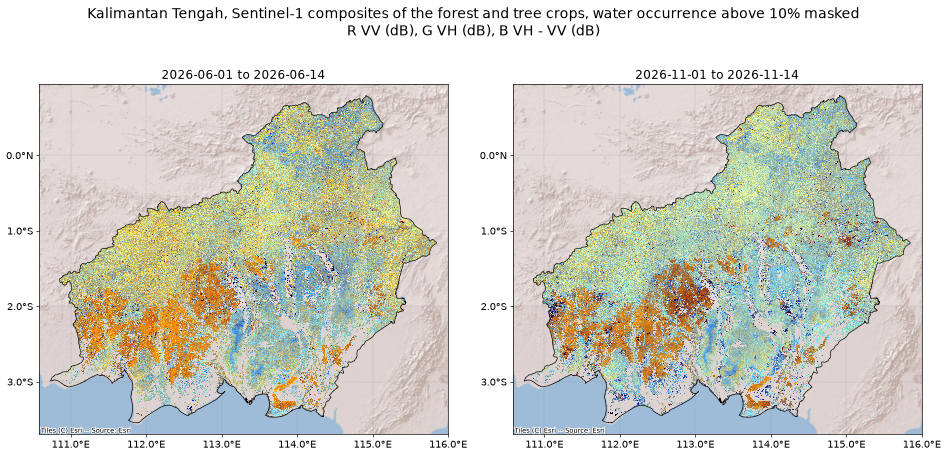

In [8]:
water_mask = np.ma.getmaskarray(occurrence) | (occurrence.filled(0) > MAX_WATER_OCCURRENCE)
other_land_mask = ~np.isin(land_cover.filled(FOREST_NODATA), FOREST_CLASSES)
mask = water_mask | other_land_mask
s1_land = {
    period: {name: np.ma.masked_where(mask, band) for name, band in bands.items()}
    for period, bands in s1.items()
}
# Shares of the pixels with Sentinel-1 data, the grid also covers the sea and the land outside the AOI
s1_valid = ~np.ma.getmaskarray(s1["before"]["vv"])
print(f"{(water_mask & s1_valid).sum() / s1_valid.sum():.1%} of the Sentinel-1 pixels masked as water or without water data")
print(f"{(other_land_mask & s1_valid).sum() / s1_valid.sum():.1%} masked as other land or without land cover data")
print(f"{(~mask & s1_valid).sum() / s1_valid.sum():.1%} kept")
map_row(
    s1_layers(s1_land),
    f"{AOI_TITLE}, Sentinel-1 composites of the forest and tree crops, water occurrence above {MAX_WATER_OCCURRENCE}% masked\n{RGB_TITLE}",
    "s1_composites_land",
)

## 6. Decrease from before to after the fire season

The change from June to November in percent of June, (November - June) / June x 100, for VV, VH and VH - VV, on the forest and tree crops of section 5. They are taken in linear values, not dB, so -50% is half the backscatter of June (-3 dB); for VH - VV it is a ratio VH / VV half that of June. Only the pixels where November is lower than June are kept, the others are masked. The darker the colour, the larger the drop.

Read the drops with care: radar backscatter also changes with soil moisture and rain, so a wet June and a dry November alone give a drop over large areas. A burned or cleared forest shows as a drop of VH (the canopy is lost) that stands out from its surroundings, often with a smaller drop of VV.

VV: lower in November on 63.8% of the forest and tree crop pixels, median decrease -11.9% of June


VH: lower in November on 42.0% of the forest and tree crop pixels, median decrease -9.5% of June


VH - VV: lower in November on 32.4% of the forest and tree crop pixels, median decrease -9.1% of June


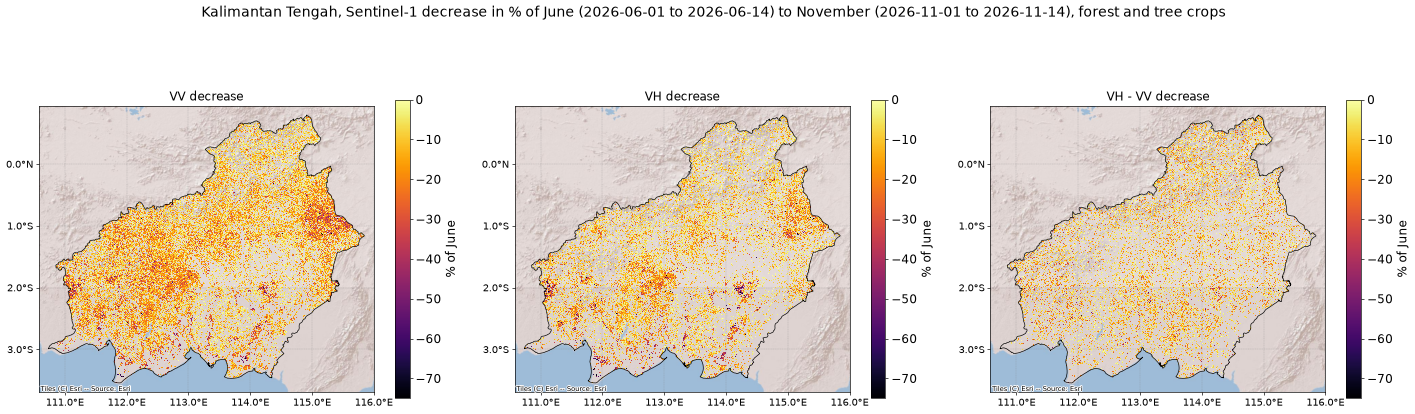

In [9]:
DIFFERENCES = {
    "vv": dict(name="VV", vmin=-75),
    "vh": dict(name="VH", vmin=-75),
    "ratio": dict(name="VH - VV", vmin=-75),
}


def linear(values):
    # From dB back to linear, VV and VH in linear power and VH - VV as the ratio VH / VV
    return 10 ** (values / 10)


decrease = {}
for band in DIFFERENCES:
    before = linear(s1_land["before"][band])
    after = linear(s1_land["after"][band])
    change = (after - before) / before * 100
    # Only where November is lower than June
    decrease[band] = np.ma.masked_where(change.filled(0) >= 0, change)
    print(
        f"{DIFFERENCES[band]['name']}: lower in November on {decrease[band].count() / change.count():.1%} of the forest and tree crop pixels, "
        f"median decrease {np.ma.median(decrease[band]):.1f}% of June"
    )

map_row(
    [
        dict(data=decrease[band], title=f"{style['name']} decrease", cmap="inferno", vmin=style["vmin"], vmax=0, label="% of June")
        for band, style in DIFFERENCES.items()
    ],
    f"{AOI_TITLE}, Sentinel-1 decrease in % of June ({PERIOD_TITLES['before']}) to November ({PERIOD_TITLES['after']}), forest and tree crops",
    "s1_decrease",
)

## 7. Decrease of more than 10%

The decreases of section 6 larger than `STRONG_DECREASE` (10%): November less than 90% of June, a drop of more than 0.46 dB. A drop this small can also come from a change of soil moisture, so look for patches that stand out from their surroundings, and compare them with the FIRMS alerts. The area is approximate, a pixel of `RESOLUTION` taken as `RESOLUTION` x `RESOLUTION` metres, about right near the equator.

VV: decrease of more than 10% on 4,791,193 pixels, 36.84% of the forest and tree crops, about 47,912 km2
VH: decrease of more than 10% on 2,618,294 pixels, 20.13% of the forest and tree crops, about 26,183 km2
VH - VV: decrease of more than 10% on 1,937,840 pixels, 14.90% of the forest and tree crops, about 19,378 km2


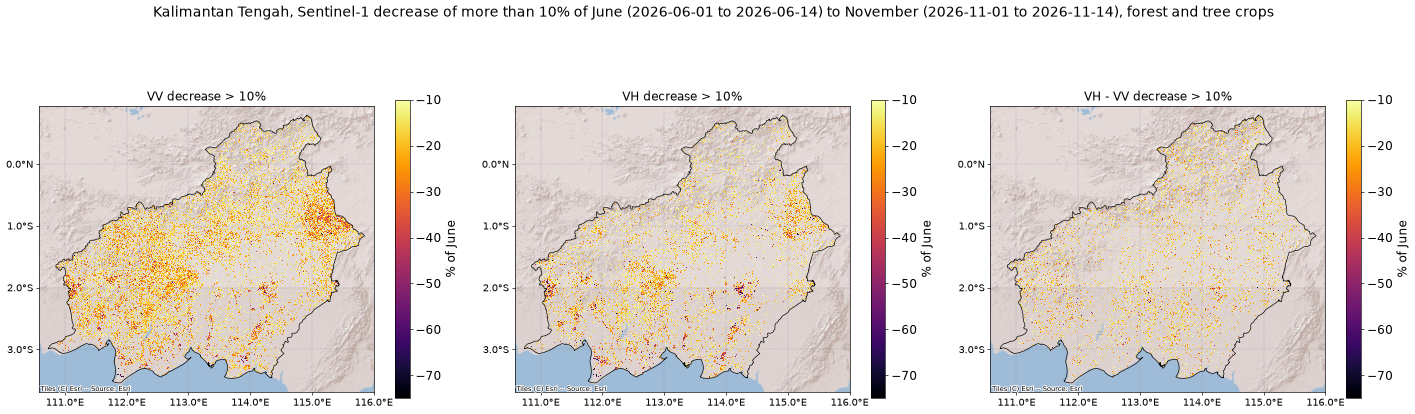

In [10]:
STRONG_DECREASE = 10

strong = {band: np.ma.masked_where(values.filled(0) > -STRONG_DECREASE, values) for band, values in decrease.items()}
for band, values in strong.items():
    area_km2 = values.count() * (RESOLUTION / 1000) ** 2
    land = s1_land["before"][band].count()
    print(
        f"{DIFFERENCES[band]['name']}: decrease of more than {STRONG_DECREASE}% on {values.count():,} pixels, "
        f"{values.count() / land:.2%} of the forest and tree crops, about {area_km2:,.0f} km2"
    )

map_row(
    [
        dict(data=strong[band], title=f"{style['name']} decrease > {STRONG_DECREASE}%", cmap="inferno", vmin=-75, vmax=-STRONG_DECREASE, label="% of June")
        for band, style in DIFFERENCES.items()
    ],
    f"{AOI_TITLE}, Sentinel-1 decrease of more than {STRONG_DECREASE}% of June ({PERIOD_TITLES['before']}) to November ({PERIOD_TITLES['after']}), forest and tree crops",
    "s1_decrease_strong",
)